In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [6]:
df = pd.read_csv("cancer.csv")

print("First five records: ")
print(df.head())

print("\nDataset Shape: ")
print(df.shape)

print("\nColumn Name:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

display(df.describe(include="all"))

First five records: 
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  peri

In [7]:
print("\nMissing values: ")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate record: ", df.duplicated().sum())

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
unique,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,3.037183e+07,NaN,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,NaN,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,NaN,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,NaN,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,NaN,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,NaN,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080



Missing values: 
Series([], dtype: int64)
Duplicate record:  0


In [8]:
df = df.drop(columns=["Unnamed: 32"], errors="ignore")

if "diagnosis" not in df.columns:
    raise ValueError("Column diagnosis was not found. Check the dataset")
df["target"] = (df["diagnosis"] == "M").astype(int)
print(df["target"].value_counts())

target
0    357
1    212
Name: count, dtype: int64


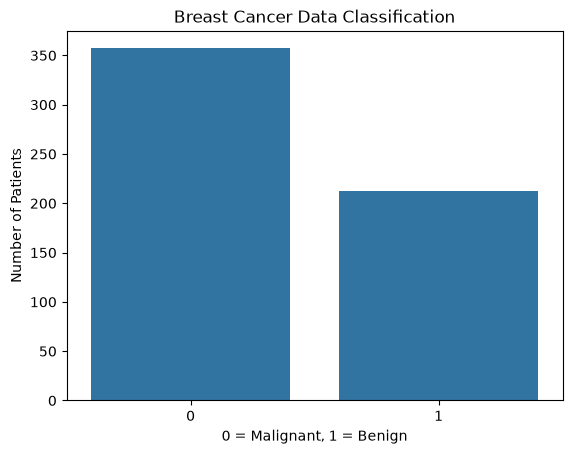

In [10]:
sns.countplot(x="target", data=df)
plt.title("Breast Cancer Data Classification")
plt.xlabel("0 = Malignant, 1 = Benign")
plt.ylabel("Number of Patients")
plt.show()

In [11]:
X = df.drop(columns=["target", "diagnosis"])
y = df["target"]


In [12]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['id', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Categorical features: []


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [14]:
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
print("Model training Completed Successfully")

Model training Completed Successfully


In [15]:
y_pred = model.predict(X_test)
print("Predicted values:")
print(y_pred[:20])


Predicted values:
[0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0]


Accuracy = 0.9211
[[71  1]
 [ 8 34]]


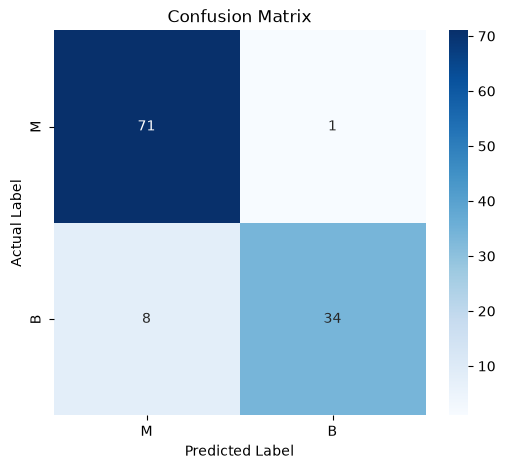

In [16]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy =", round(accuracy, 4))

cm = confusion_matrix(y_test, y_pred)
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=df['diagnosis'].unique(),
    yticklabels=df['diagnosis'].unique()
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [17]:
precision = precision_score(y_test, y_pred)
print("Precision =", round(precision, 4))

recall = recall_score(y_test, y_pred)
print("Recall =", round(recall, 4))

f1 = f1_score(y_test, y_pred)
print("F1-Score = ", round(f1, 4))

report = classification_report(
    y_test, y_pred, target_names=["Benign", "Malignant"]
)
print(report)

Precision = 0.9714
Recall = 0.8095
F1-Score =  0.8831
              precision    recall  f1-score   support

      Benign       0.90      0.99      0.94        72
   Malignant       0.97      0.81      0.88        42

    accuracy                           0.92       114
   macro avg       0.94      0.90      0.91       114
weighted avg       0.93      0.92      0.92       114



In [18]:
print("...Model Performance...")

print("Accuracy :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall :", round(recall, 4))
print("F1 Score :", round(f1, 4))

...Model Performance...
Accuracy : 0.9211
Precision : 0.9714
Recall : 0.8095
F1 Score : 0.8831
